In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Configuração de estilo para os gráficos, o nome parece muito legal
plt.style.use('seaborn-v0_8')

# Lendo a base e inserindo na variavel
file = "winequality-red.csv"
data = pd.read_csv(file, sep = ";")
data


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.700,0.00,1.9,0.076,11.0,34.0,0.99780,3.51,0.56,9.4,5
1,7.8,0.880,0.00,2.6,0.098,25.0,67.0,0.99680,3.20,0.68,9.8,5
2,7.8,0.760,0.04,2.3,0.092,15.0,54.0,0.99700,3.26,0.65,9.8,5
3,11.2,0.280,0.56,1.9,0.075,17.0,60.0,0.99800,3.16,0.58,9.8,6
4,7.4,0.700,0.00,1.9,0.076,11.0,34.0,0.99780,3.51,0.56,9.4,5
...,...,...,...,...,...,...,...,...,...,...,...,...
1594,6.2,0.600,0.08,2.0,0.090,32.0,44.0,0.99490,3.45,0.58,10.5,5
1595,5.9,0.550,0.10,2.2,0.062,39.0,51.0,0.99512,3.52,0.76,11.2,6
1596,6.3,0.510,0.13,2.3,0.076,29.0,40.0,0.99574,3.42,0.75,11.0,6
1597,5.9,0.645,0.12,2.0,0.075,32.0,44.0,0.99547,3.57,0.71,10.2,5


In [2]:
print("\n\n\n\nENLOUQUECI\n\n\n\n")





ENLOUQUECI






In [3]:
# Separando a base entre treino e teste, sendo que 80% das linhas da 
# base original serão designadas a treino e 20% a teste

train_data = data.sample(frac = 0.8, random_state = 42)
test_data = data.drop(train_data.index)

X_train = train_data.drop(columns = "quality")
y_train = train_data["quality"]

X_test = test_data.drop(columns = "quality")
y_test = test_data["quality"]

#####################################################################


# Convertendo os dados para matrizes numericas
X_train_m = X_train.to_numpy(dtype = float)
y_treino = y_train.to_numpy(dtype = float)
X_valuation = X_test.to_numpy(dtype = float)
y_valuation = y_test.to_numpy(dtype = float)

# adiciona uma coluna de 1 para o intercepto
X_intercept_train = np.column_stack(
    [np.ones(len(X_train_m)), X_train_m]
)
X_intercept_valuation = np.column_stack(
    [np.ones(len(X_valuation)), X_valuation]
)

# Ajusta os coeficientes usando os dados de treino
coefficients, *_ = np.linalg.lstsq(
    X_intercept_train, y_train, rcond = None
)

# Calcula as previsões para os dados de avaliação
prediction = X_intercept_valuation @ coefficients

# Associa cada coeficiente ao nome da respectiva variável
names = ["intercept"] + list(X_train.columns)
coefficients_result = pd.Series(coefficients, index = names)

coefficients_result

intercept               22.464534
fixed acidity            0.006538
volatile acidity        -0.952018
citric acid             -0.086144
residual sugar           0.009590
chlorides               -1.923678
free sulfur dioxide      0.004930
total sulfur dioxide    -0.003642
density                -17.443395
pH                      -0.659216
sulphates                0.985946
alcohol                  0.269186
dtype: float64

In [4]:
errors = y_valuation - prediction

mae = np.mean(np.abs(errors))
rmse = np.sqrt(np.mean(errors ** 2))

quadract_error_sum = np.sum(errors ** 2)
quadract_total_sum = np.sum((y_valuation - np.mean(y_valuation)) ** 2)
r2 = 1 - quadract_error_sum / quadract_total_sum

print("MAE:", mae)
print("RMSE:", rmse)
print("R²:", r2)

MAE: 0.4387322631200231
RMSE: 0.5916770960456842
R²: 0.42239664080836703


In [5]:
distribution_summary = data.describe().T
distribution_summary["skewness"] = data.skew()

distribution_summary[
    ["mean", "std", "min", "25%", "50%", "75%", "max", "skewness"]
]

,mean,std,min,25%,50%,75%,max,skewness
fixed acidity,8.319637,1.741096,4.60000,7.1000,7.90000,9.200000,15.90000,0.982751
volatile acidity,0.527821,0.179060,0.12000,0.3900,0.52000,0.640000,1.58000,0.671593
citric acid,0.270976,0.194801,0.00000,0.0900,0.26000,0.420000,1.00000,0.318337
residual sugar,2.538806,1.409928,0.90000,1.9000,2.20000,2.600000,15.50000,4.540655
chlorides,0.087467,0.047065,0.01200,0.0700,0.07900,0.090000,0.61100,5.680347
free sulfur dioxide,15.874922,10.460157,1.00000,7.0000,14.00000,21.000000,72.00000,1.250567
total sulfur dioxide,46.467792,32.895324,6.00000,22.0000,38.00000,62.000000,289.00000,1.515531
density,0.996747,0.001887,0.99007,0.9956,0.99675,0.997835,1.00369,0.071288
pH,3.311113,0.154386,2.74000,3.2100,3.31000,3.400000,4.01000,0.193683
sulphates,0.658149,0.169507,0.33000,0.5500,0.62000,0.730000,2.00000,2.428672


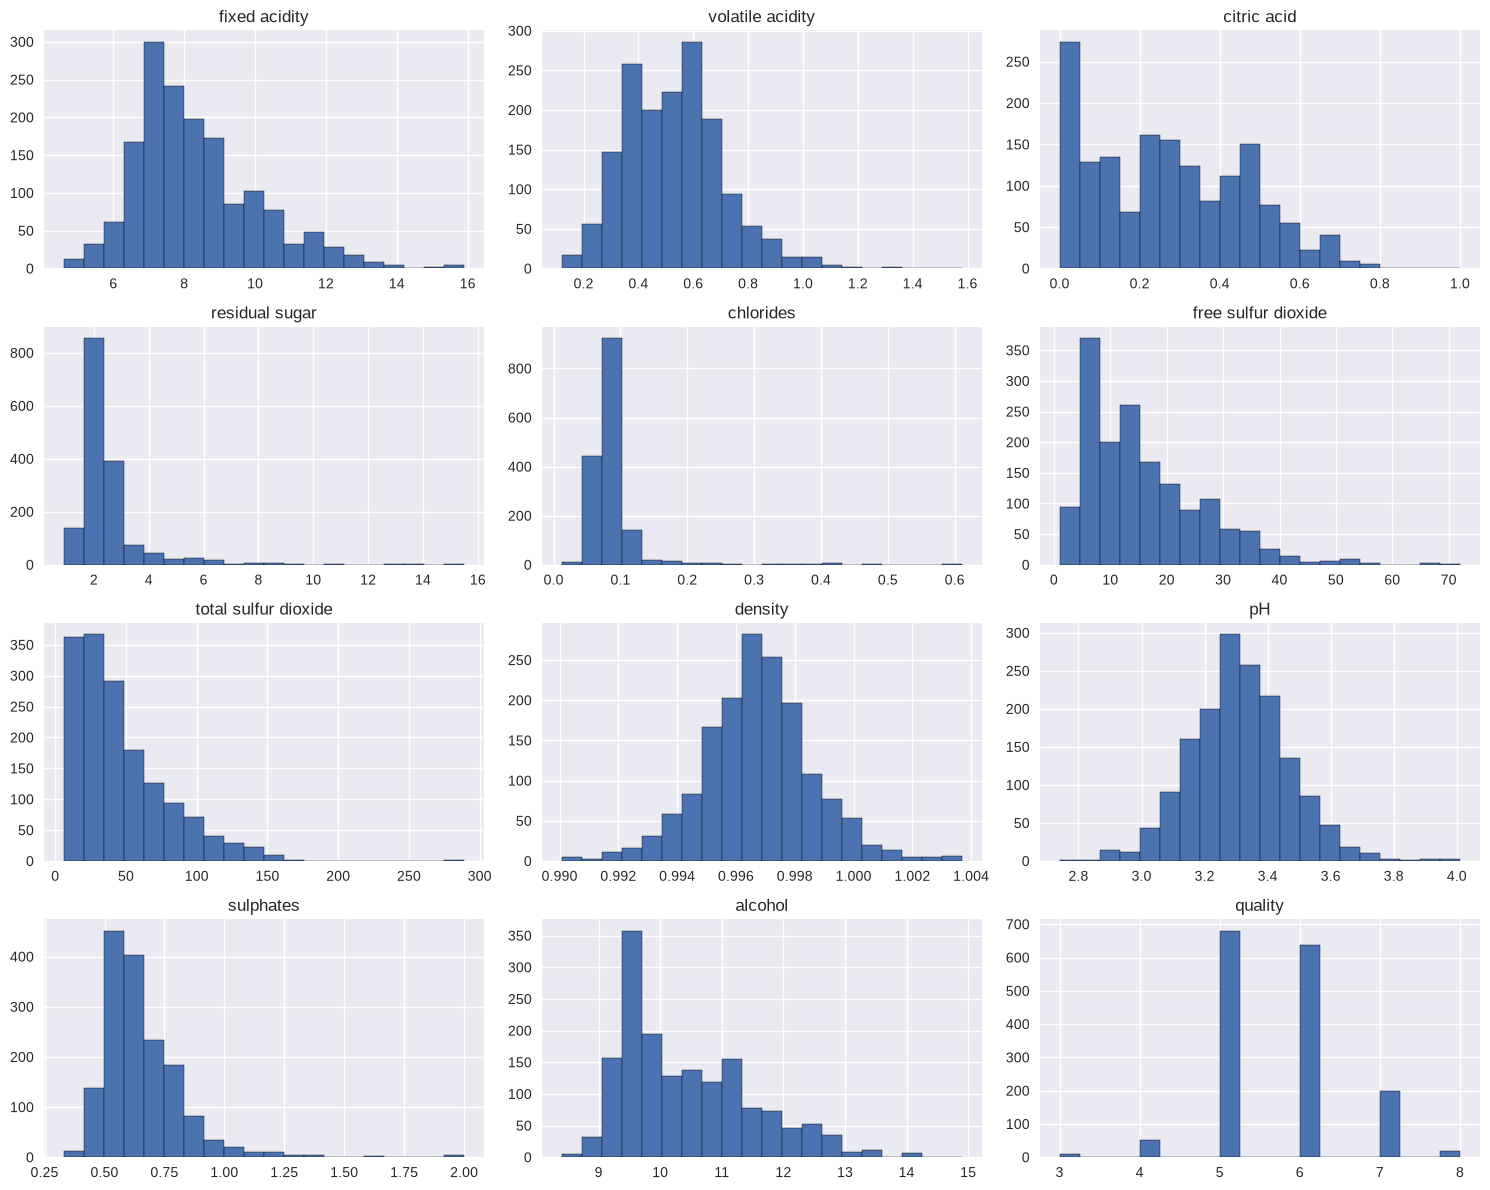

In [6]:
data.hist(bins = 20, figsize = (15, 12), edgecolor = "black")
plt.tight_layout()
plt.show()

In [7]:
correlation_matrix = data.corr()

correlation_matrix.round(2)

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
fixed acidity,1.00,-0.26,0.67,0.11,0.09,-0.15,-0.11,0.67,-0.68,0.18,-0.06,0.12
volatile acidity,-0.26,1.00,-0.55,0.00,0.06,-0.01,0.08,0.02,0.23,-0.26,-0.20,-0.39
citric acid,0.67,-0.55,1.00,0.14,0.20,-0.06,0.04,0.36,-0.54,0.31,0.11,0.23
residual sugar,0.11,0.00,0.14,1.00,0.06,0.19,0.20,0.36,-0.09,0.01,0.04,0.01
chlorides,0.09,0.06,0.20,0.06,1.00,0.01,0.05,0.20,-0.27,0.37,-0.22,-0.13
free sulfur dioxide,-0.15,-0.01,-0.06,0.19,0.01,1.00,0.67,-0.02,0.07,0.05,-0.07,-0.05
total sulfur dioxide,-0.11,0.08,0.04,0.20,0.05,0.67,1.00,0.07,-0.07,0.04,-0.21,-0.19
density,0.67,0.02,0.36,0.36,0.20,-0.02,0.07,1.00,-0.34,0.15,-0.50,-0.17
pH,-0.68,0.23,-0.54,-0.09,-0.27,0.07,-0.07,-0.34,1.00,-0.20,0.21,-0.06
sulphates,0.18,-0.26,0.31,0.01,0.37,0.05,0.04,0.15,-0.20,1.00,0.09,0.25


In [8]:
correlation_matrix["quality"].drop("quality").sort_values()

volatile acidity       -0.390558
total sulfur dioxide   -0.185100
density                -0.174919
chlorides              -0.128907
pH                     -0.057731
free sulfur dioxide    -0.050656
residual sugar          0.013732
fixed acidity           0.124052
citric acid             0.226373
sulphates               0.251397
alcohol                 0.476166
Name: quality, dtype: float64

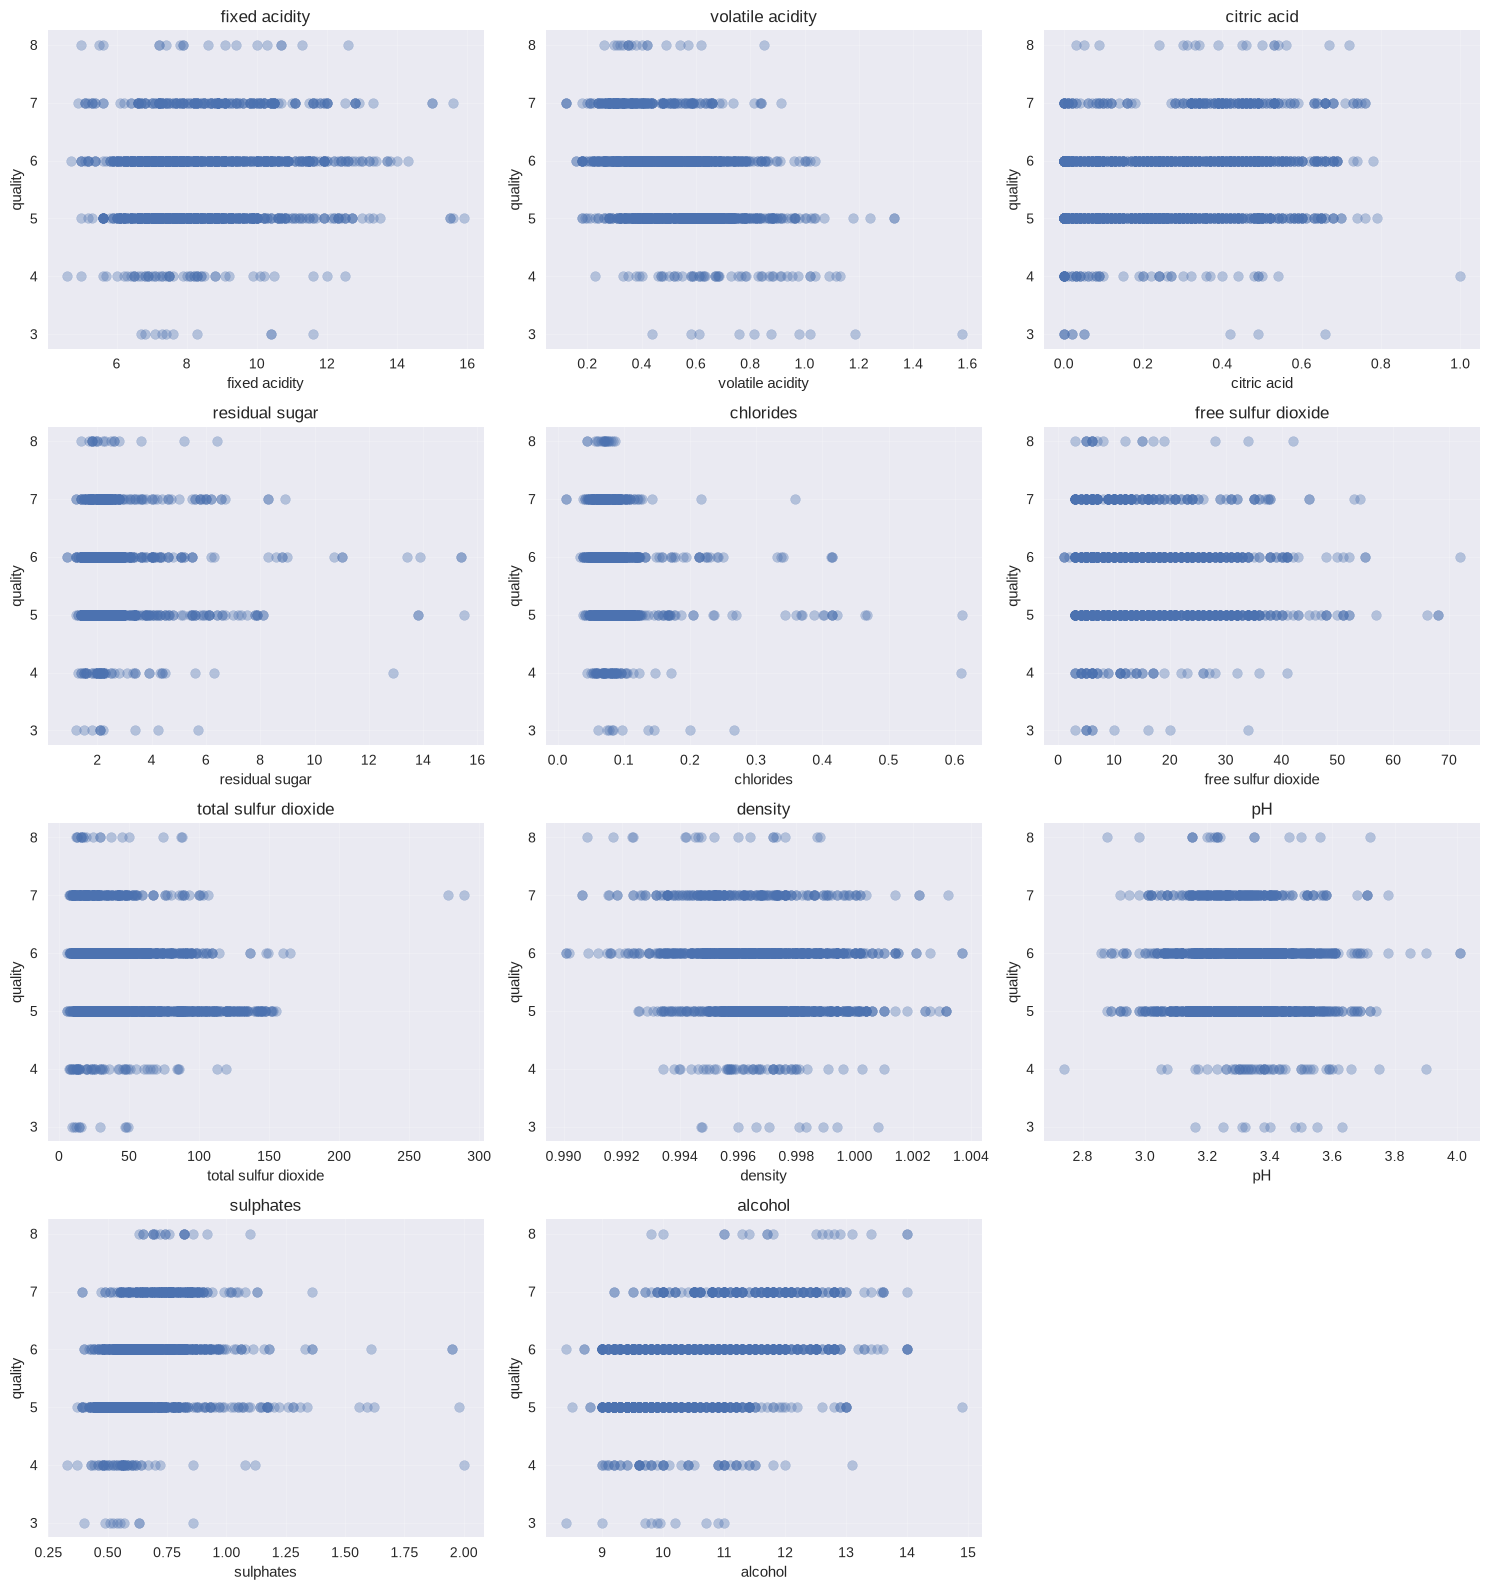

In [9]:
predictors = data.drop(columns = "quality").columns

fig, axes = plt.subplots(4, 3, figsize = (15, 16))
axes = axes.flatten()

for i, column in enumerate(predictors):
    axes[i].scatter(data[column], data["quality"], alpha = 0.35)
    axes[i].set_title(column)
    axes[i].set_xlabel(column)
    axes[i].set_ylabel("quality")
    axes[i].grid(True, alpha = 0.2)

for ax in axes[len(predictors):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

In [10]:
import statsmodels.api as sm

def fit_model(features):
    if features:
        X_model = sm.add_constant(
            X_train[features],
            has_constant = "add"
        )
    else:
        X_model = pd.DataFrame(
            {"const": np.ones(len(y_train))},
            index = y_train.index
        )

    return sm.OLS(y_train, X_model).fit()


selected_features = []
current_model = fit_model(selected_features)
current_aic = current_model.aic
selection_changed = True

while selection_changed:
    selection_changed = False

    # Testa adicionar cada variável ainda não selecionada
    remaining_features = [
        feature for feature in X_train.columns
        if feature not in selected_features
    ]

    addition_models = []

    for feature in remaining_features:
        features_try = selected_features + [feature]
        model_try = fit_model(features_try)
        addition_models.append((model_try.aic, feature, model_try))

    if addition_models:
        best_aic, best_feature, best_model = min(
            addition_models,
            key = lambda item: item[0]
        )

        if best_aic < current_aic:
            selected_features.append(best_feature)
            current_model = best_model
            current_aic = best_aic
            selection_changed = True

    # Testa remover cada variável selecionada
    while selected_features:
        removal_models = []

        for feature in selected_features:
            features_try = [
                selected_feature
                for selected_feature in selected_features
                if selected_feature != feature
            ]
            model_try = fit_model(features_try)
            removal_models.append((model_try.aic, feature, model_try))

        best_aic, feature_to_remove, best_model = min(
            removal_models,
            key = lambda item: item[0]
        )

        if best_aic < current_aic:
            selected_features.remove(feature_to_remove)
            current_model = best_model
            current_aic = best_aic
            selection_changed = True
        else:
            break


print("Variáveis selecionadas:", selected_features)
print("AIC final:", current_model.aic)
current_model.summary()

Variáveis selecionadas: ['alcohol', 'volatile acidity', 'sulphates', 'total sulfur dioxide', 'pH', 'chlorides', 'free sulfur dioxide']
AIC final: 2583.3219730623487


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                quality   R-squared:                       0.343
Model:                            OLS   Adj. R-squared:                  0.339
Method:                 Least Squares   F-statistic:                     94.74
Date:                Mon, 26 Oct 2026   Prob (F-statistic):          2.78e-111
Time:                        12:24:49   Log-Likelihood:                -1283.7
No. Observations:                1279   AIC:                             2583.
Df Residuals:                    1271   BIC:                             2625.
Df Model:                           7                                         
Covariance Type:            nonrobust                                         
========================================================================================
                           coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------
const                    4.8877      0.454     10.763      0.000       3.997       5.779
alcohol                  0.2836      0.019     14.730      0.000       0.246       0.321
volatile acidity        -0.9220      0.115     -8.025      0.000      -1.147      -0.697
sulphates                0.9443      0.129      7.301      0.000       0.691       1.198
total sulfur dioxide    -0.0037      0.001     -4.670      0.000      -0.005      -0.002
pH                      -0.6279      0.134     -4.693      0.000      -0.890      -0.365
chlorides               -1.9437      0.445     -4.371      0.000      -2.816      -1.071
free sulfur dioxide      0.0053      0.002      2.158      0.031       0.000       0.010
==============================================================================
Omnibus:                       14.002   Durbin-Watson:                   1.976
Prob(Omnibus):                  0.001   Jarque-Bera (JB):               18.255
Skew:                          -0.138   Prob(JB):                     0.000109
Kurtosis:                       3.517   Cond. No.                     1.67e+03
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 1.67e+03. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

In [16]:
X_test_selected = sm.add_constant(
    X_test[selected_features],
    has_constant = "add"
)

y_test_values = y_test.to_numpy(dtype = float)
prediction_selected = current_model.predict(X_test_selected)
errors_selected = y_test_values - prediction_selected

prediction_selected_integer = np.floor(
    prediction_selected + 0.5
).astype(int)

errors_selected_integer = y_test_values - prediction_selected_integer

test_total_sum = np.sum(
    (y_test_values - np.mean(y_test_values)) ** 2
)

mae_selected = np.mean(np.abs(errors_selected))
rmse_selected = np.sqrt(np.mean(errors_selected ** 2))
r2_selected = 1 - np.sum(errors_selected ** 2) / test_total_sum

mae_selected_integer = np.mean(np.abs(errors_selected_integer))
rmse_selected_integer = np.sqrt(np.mean(errors_selected_integer ** 2))
r2_selected_integer = (
    1 - np.sum(errors_selected_integer ** 2) / test_total_sum
)

print("Previsões decimais\n")
print("MAE:", mae_selected)
print("RMSE:", rmse_selected)
print("R²:", r2_selected)

print("\n\nPrevisões arredondadas\n")
print("MAE:", mae_selected_integer)
print("RMSE:", rmse_selected_integer)
print("R²:", r2_selected_integer)

Previsões decimais

MAE: 0.438091212062439
RMSE: 0.5907398603881145
R²: 0.42422507631637996


Previsões arredondadas

MAE: 0.371875
RMSE: 0.649519052838329
R²: 0.3039443155452435


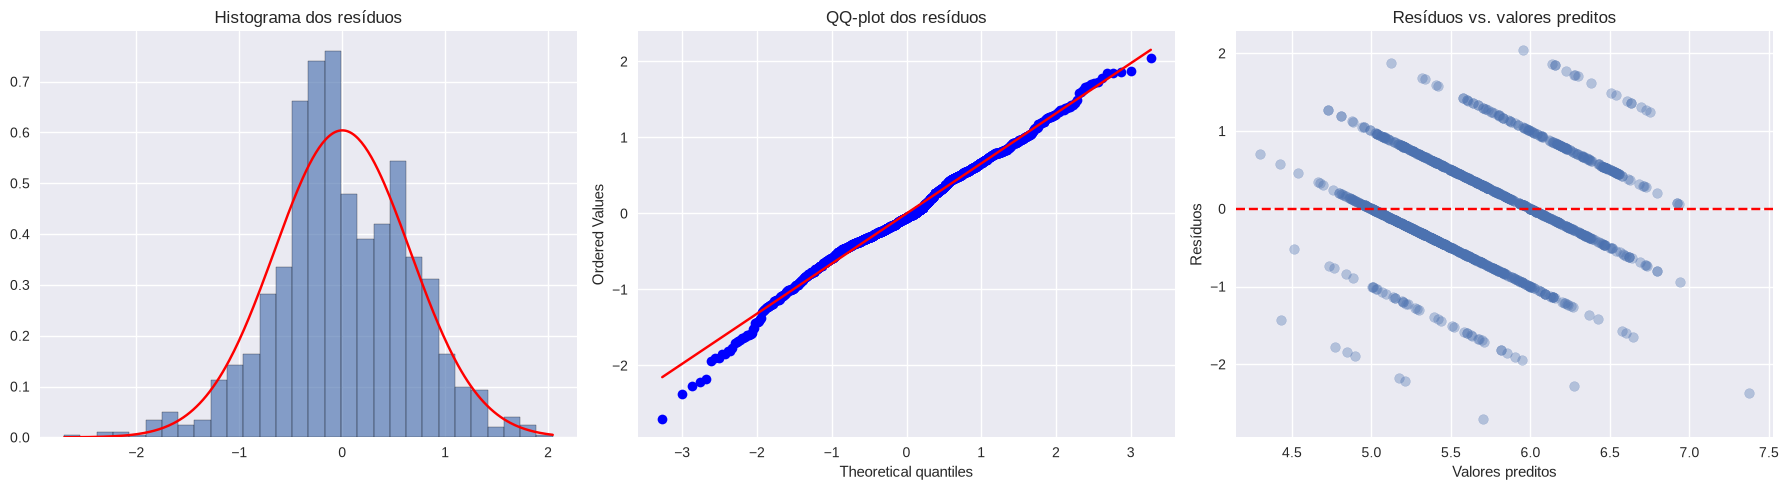

In [17]:
from scipy.stats import norm, probplot
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.stattools import jarque_bera

residuals = current_model.resid
fitted_values = current_model.fittedvalues

fig, axes = plt.subplots(1, 3, figsize = (18, 5))

# Histograma dos resíduos e curva normal de referência
axes[0].hist(
    residuals,
    bins = 30,
    density = True,
    alpha = 0.65,
    edgecolor = "black"
)
curve_x = np.linspace(residuals.min(), residuals.max(), 300)
axes[0].plot(
    curve_x,
    norm.pdf(
        curve_x,
        loc = residuals.mean(),
        scale = residuals.std(ddof = 1)
    ),
    color = "red"
)
axes[0].set_title("Histograma dos resíduos")

# QQ-plot contra a distribuição normal
probplot(residuals, dist = "norm", plot = axes[1])
axes[1].set_title("QQ-plot dos resíduos")

# Resíduos contra valores preditos
axes[2].scatter(fitted_values, residuals, alpha = 0.35)
axes[2].axhline(0, color = "red", linestyle = "--")
axes[2].set_title("Resíduos vs. valores preditos")
axes[2].set_xlabel("Valores preditos")
axes[2].set_ylabel("Resíduos")

plt.tight_layout()
plt.show()

In [18]:
jb_statistic, jb_pvalue, residual_skewness, residual_kurtosis = (
    jarque_bera(residuals)
)

bp_lm_statistic, bp_lm_pvalue, bp_f_statistic, bp_f_pvalue = (
    het_breuschpagan(residuals, current_model.model.exog)
)

print("Jarque-Bera p-valor:", jb_pvalue)
print("Breusch-Pagan p-valor:", bp_lm_pvalue)

Jarque-Bera p-valor: 0.00010865982190542435
Breusch-Pagan p-valor: 2.713829869427612e-08
